In [15]:
!pip install tensorflow keras numpy pillow matplotlib scikit-learn flask

In [16]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from PIL import Image
import random


In [17]:
PROJECT_DIR = r"D:\CSE Code\CSE465 Project"
SOURCE_TRAIN_DIR = os.path.join(PROJECT_DIR, "Dataset", "train")
TRAIN_DIR = os.path.join(PROJECT_DIR, "dataset", "train")
VAL_DIR = os.path.join(PROJECT_DIR, "dataset", "validation")

print(f"Project Directory: {PROJECT_DIR}")
print(f"Source Train Directory: {SOURCE_TRAIN_DIR}")
print(f"Output Train Directory: {TRAIN_DIR}")
print(f"Output Validation Directory: {VAL_DIR}")


Project Directory: D:\CSE Code\CSE465 Project
Source Train Directory: D:\CSE Code\CSE465 Project\Dataset\train
Output Train Directory: D:\CSE Code\CSE465 Project\dataset\train
Output Validation Directory: D:\CSE Code\CSE465 Project\dataset\validation


In [18]:
fake_images = [f for f in os.listdir(os.path.join(SOURCE_TRAIN_DIR, "fake")) 
               if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
real_images = [f for f in os.listdir(os.path.join(SOURCE_TRAIN_DIR, "real")) 
               if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

print(f"Total Fake Images in Dataset/train: {len(fake_images)}")
print(f"Total Real Images in Dataset/train: {len(real_images)}")
print(f"Total Images: {len(fake_images) + len(real_images)}")

Total Fake Images in Dataset/train: 2933
Total Real Images in Dataset/train: 3861
Total Images: 6794


In [19]:
os.makedirs(os.path.join(TRAIN_DIR, "fake"), exist_ok=True)
os.makedirs(os.path.join(TRAIN_DIR, "real"), exist_ok=True)
os.makedirs(os.path.join(VAL_DIR, "fake"), exist_ok=True)
os.makedirs(os.path.join(VAL_DIR, "real"), exist_ok=True)
os.makedirs(os.path.join(PROJECT_DIR, "model"), exist_ok=True)

print("Directories created successfully!")


Directories created successfully!


In [20]:
def prepare_dataset():
    """
    Split Dataset/train into train and validation sets (80/20 split)
    """
    for class_name in ["fake", "real"]:
        source_dir = os.path.join(SOURCE_TRAIN_DIR, class_name)
        images = [f for f in os.listdir(source_dir) 
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        # Split data: 80% train, 20% validation
        train_images, val_images = train_test_split(images, test_size=0.2, random_state=42)
        
        # Copy to train directory
        print(f"\nCopying {class_name} training images...")
        for img in train_images:
            src = os.path.join(source_dir, img)
            dst = os.path.join(TRAIN_DIR, class_name, img)
            if not os.path.exists(dst):
                shutil.copy2(src, dst)
        
        # Copy to validation directory
        print(f"Copying {class_name} validation images...")
        for img in val_images:
            src = os.path.join(source_dir, img)
            dst = os.path.join(VAL_DIR, class_name, img)
            if not os.path.exists(dst):
                shutil.copy2(src, dst)
        
        print(f"{class_name.capitalize()}: {len(train_images)} train, {len(val_images)} validation")

prepare_dataset()



Copying fake training images...
Copying fake validation images...
Fake: 2346 train, 587 validation

Copying real training images...
Copying real validation images...
Real: 3088 train, 773 validation


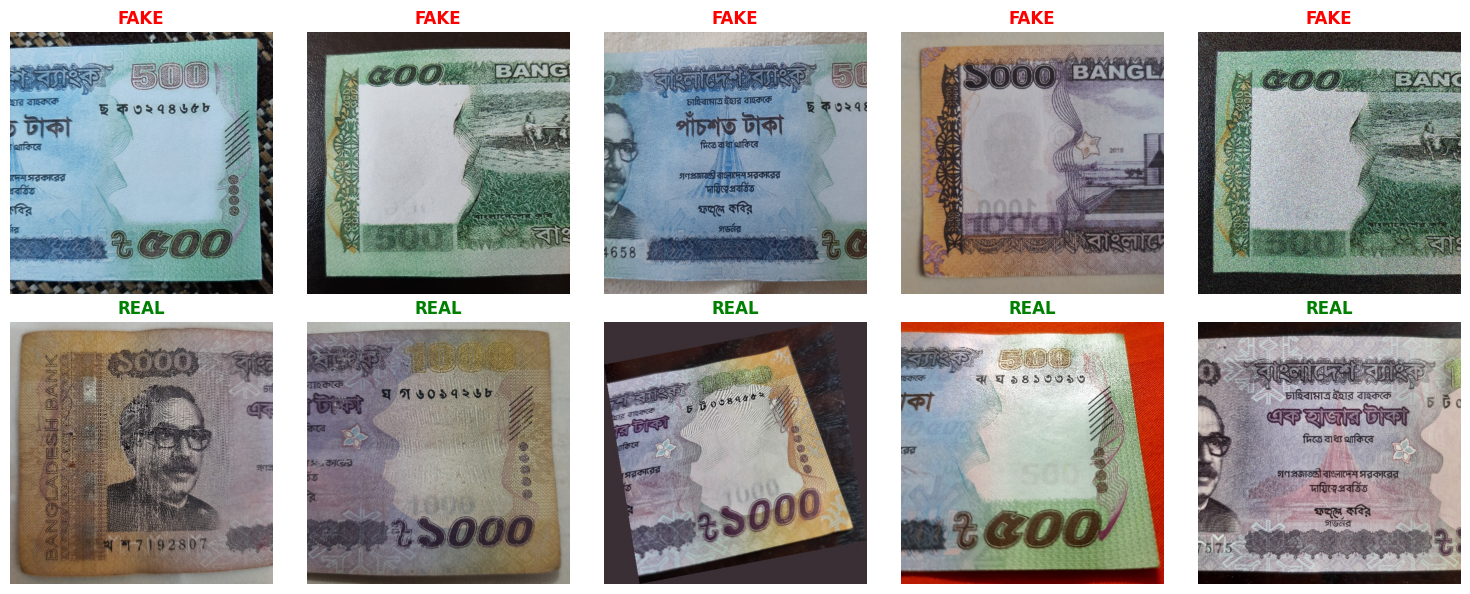

Dataset preparation complete!


In [21]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Show fake samples
fake_samples = random.sample(os.listdir(os.path.join(TRAIN_DIR, "fake")), 5)
for idx, img_name in enumerate(fake_samples):
    img_path = os.path.join(TRAIN_DIR, "fake", img_name)
    img = Image.open(img_path)
    axes[0, idx].imshow(img)
    axes[0, idx].set_title("FAKE", color='red', fontweight='bold')
    axes[0, idx].axis('off')

# Show real samples
real_samples = random.sample(os.listdir(os.path.join(TRAIN_DIR, "real")), 5)
for idx, img_name in enumerate(real_samples):
    img_path = os.path.join(TRAIN_DIR, "real", img_name)
    img = Image.open(img_path)
    axes[1, idx].imshow(img)
    axes[1, idx].set_title("REAL", color='green', fontweight='bold')
    axes[1, idx].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "sample_images.png"), dpi=150)
plt.show()

print("Dataset preparation complete!")